<a href="https://colab.research.google.com/github/SriVarshiniD/NIE-ML2/blob/main/ML2Lab8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install MiniSom

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for MiniSom: filename=minisom-2.3.6-py3-none-any.whl size=13171 sha256=fdc3826c4f8d15b53f24a9519ba2786c7c9e75e295a8a1453a023cdb6af69c68
  Stored in directory: /root/.cache/pip/wheels/dc/11/f9/32be492f07fa741d7dcff82007abc966a324da6ab9ceb198e3
Successfully built MiniSom


First 5 rows of dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2

Dataset Shape: (150, 4)

SOM Training Completed!


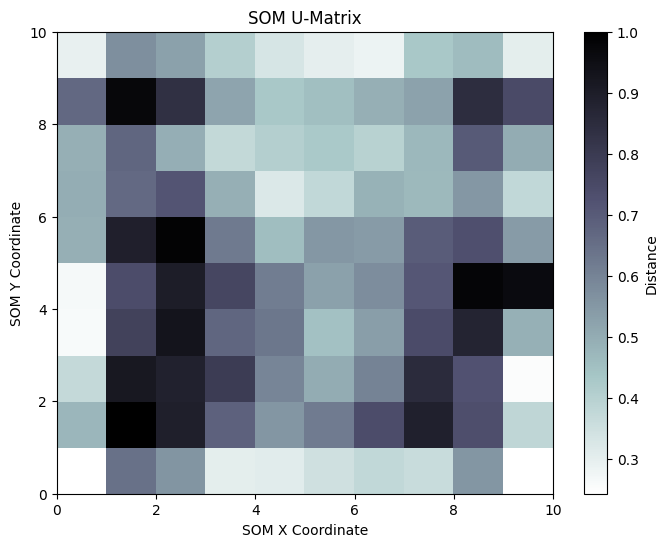

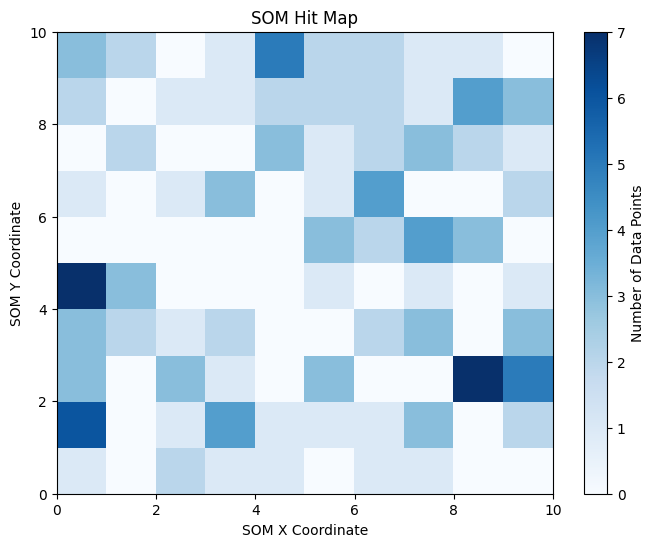

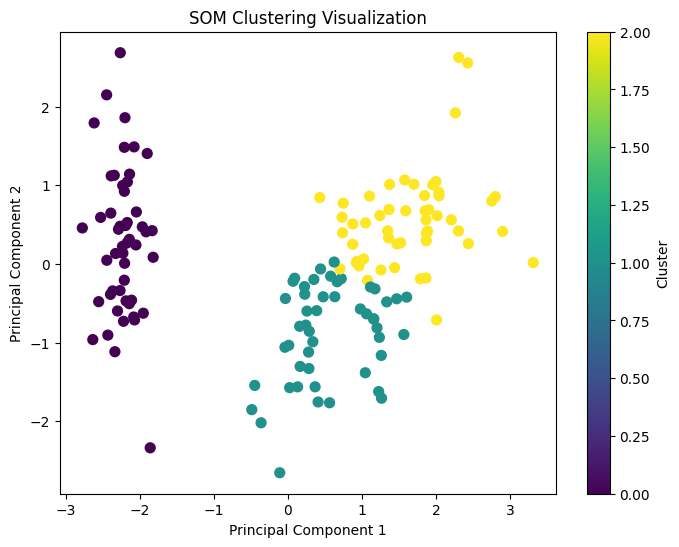

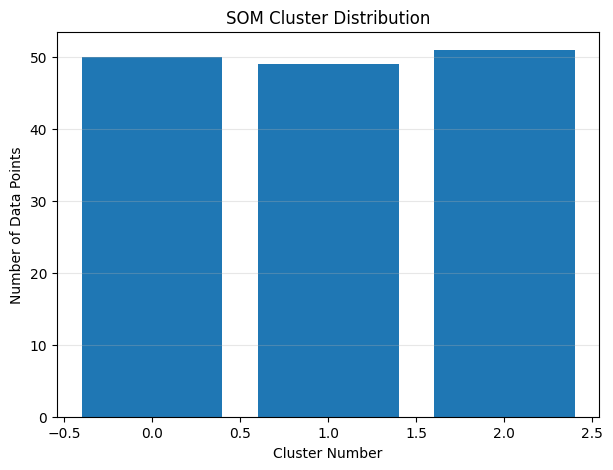


Final Cluster Distribution:
Cluster 0 : 50 data points
Cluster 1 : 49 data points
Cluster 2 : 51 data points

SOM Clustering Completed!


In [ ]:

# PROGRAM 8: SELF-ORGANIZING MAP (SOM)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from minisom import MiniSom

# --------------------------------
# 1. LOAD DATASET
# --------------------------------

iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

print("First 5 rows of dataset:")
print(X.head())

print("\nDataset Shape:", X.shape)

# --------------------------------
# 2. DATA PREPROCESSING
# --------------------------------

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

# --------------------------------
# 3. INITIALIZE SOM
# --------------------------------

som = MiniSom(
    x=10,
    y=10,
    input_len=4,
    sigma=1.0,
    learning_rate=0.5,
    random_seed=42
)

# Initialize weights
som.random_weights_init(X_scaled)

# Train SOM
som.train_random(
    X_scaled,
    num_iteration=1000
)

print("\nSOM Training Completed!")

# --------------------------------
# 4. U-MATRIX VISUALIZATION
# --------------------------------

plt.figure(figsize=(8, 6))

plt.pcolor(
    som.distance_map().T,
    cmap='bone_r'
)

plt.colorbar(label='Distance')

plt.title("SOM U-Matrix")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")

plt.show()

# --------------------------------
# 5. HIT MAP VISUALIZATION
# --------------------------------

hits = som.activation_response(X_scaled)

plt.figure(figsize=(8, 6))

plt.pcolor(
    hits.T,
    cmap='Blues'
)

plt.colorbar(label='Number of Data Points')

plt.title("SOM Hit Map")
plt.xlabel("SOM X Coordinate")
plt.ylabel("SOM Y Coordinate")

plt.show()

# --------------------------------
# 6. ASSIGN CLUSTERS TO NEURONS
# --------------------------------

weights = som.get_weights()

# Cluster the trained neuron weights
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

neuron_clusters = kmeans.fit_predict(
    weights.reshape(-1, 4)
)

neuron_clusters = neuron_clusters.reshape(10, 10)

# Assign each data point to its neuron's cluster
data_clusters = []

for sample in X_scaled:

    winner = som.winner(sample)

    cluster = neuron_clusters[winner[0], winner[1]]

    data_clusters.append(cluster)

data_clusters = np.array(data_clusters)

# --------------------------------
# 7. PCA SCATTER PLOT
# --------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=data_clusters,
    cmap='viridis',
    s=50
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("SOM Clustering Visualization")

plt.colorbar(label="Cluster")

plt.show()

# --------------------------------
# 8. CLUSTER DISTRIBUTION
# --------------------------------

cluster_counts = pd.Series(
    data_clusters
).value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    cluster_counts.index,
    cluster_counts.values
)

plt.xlabel("Cluster Number")
plt.ylabel("Number of Data Points")

plt.title("SOM Cluster Distribution")

plt.grid(axis='y', alpha=0.3)

plt.show()

# --------------------------------
# 9. DISPLAY FINAL RESULTS
# --------------------------------

print("\nFinal Cluster Distribution:")

for cluster, count in cluster_counts.items():

    print(
        "Cluster", cluster,
        ":", count, "data points"
    )

print("\nSOM Clustering Completed!")
